Slashdot0811: nodes=77360, edges=828161, avg clustering=0.0532
Slashdot0902: nodes=82168, edges=870161, avg clustering=0.0572


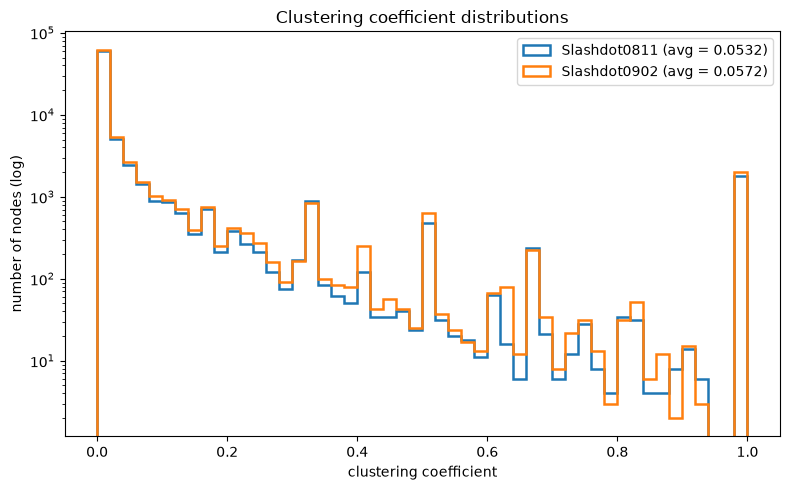

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def load(path):
    G = nx.read_edgelist(path, comments="#", create_using=nx.DiGraph, nodetype=int)
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G

graphs = {"Slashdot0811": load("data/Slashdot0811.txt"),
          "Slashdot0902": load("data/Slashdot0902.txt")}

coeffs, averages = {}, {}
for name, G in graphs.items():
    c = nx.clustering(G)
    coeffs[name] = np.array(list(c.values()))
    averages[name] = coeffs[name].mean()
    print(f"{name}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
          f"avg clustering={averages[name]:.4f}")

bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(8, 5))
for (name, c), color in zip(coeffs.items(), ["tab:blue", "tab:orange"]):
    ax.hist(c, bins=bins, histtype="step", linewidth=1.8, color=color,
            label=f"{name} (avg = {averages[name]:.4f})")

ax.set_yscale("log")
ax.set_xlabel("clustering coefficient")
ax.set_ylabel("number of nodes (log)")
ax.set_title("Clustering coefficient distributions")
ax.legend()
plt.tight_layout()
plt.show()

Average degree : 21.180045759906534
Endpoints: (5, 5000) and (1000, 1)
gamma = 1.608


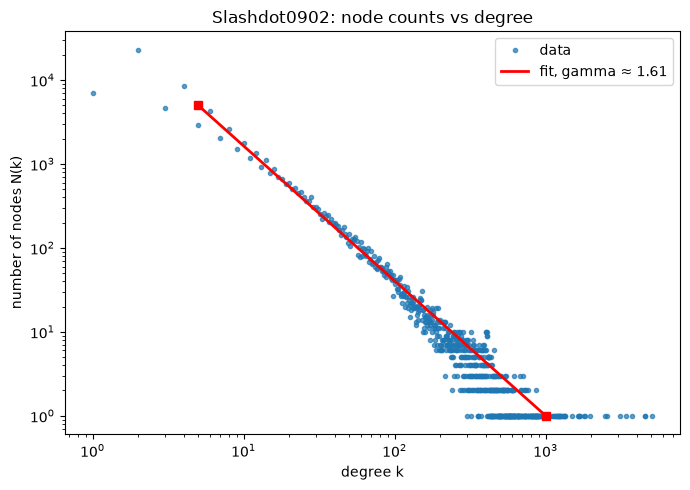

In [2]:
from collections import Counter

G = graphs["Slashdot0902"]

deg_tot = dict(G.degree())
print("Average degree :", np.mean(list(deg_tot.values())))

def plot_counts(deg, ax):
    counts = Counter(deg.values())
    counts.pop(0, None)
    k = np.array(sorted(counts))
    N = np.array([counts[x] for x in k])
    ax.loglog(k, N, "o", markersize=3, alpha=0.7, label="data")


k1, N1 = 5, 5000
k2, N2 = 1000, 1

gamma = np.log(N1 / N2) / np.log(k2 / k1)
print(f"Endpoints: ({k1}, {N1}) and ({k2}, {N2})")
print(f"gamma = {gamma:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_counts(deg_tot, ax)
ax.loglog([k1, k2], [N1, N2], "r-", linewidth=2,
          label=f"fit, gamma ≈ {gamma:.2f}")
ax.plot([k1, k2], [N1, N2], "rs", markersize=6)
ax.set_xlabel("degree k")
ax.set_ylabel("number of nodes N(k)")
ax.set_title("Slashdot0902: node counts vs degree")
ax.legend()
plt.tight_layout()
plt.show()

Average degree : 21.410573940020683
Endpoints: (5, 5000) and (800, 1)
gamma = 1.678


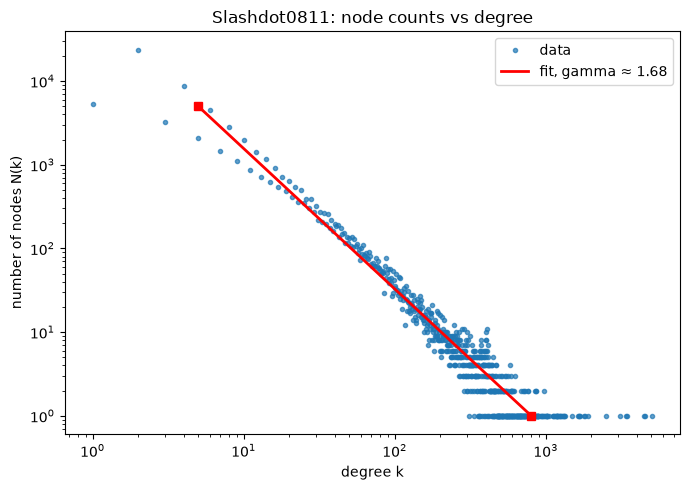

In [3]:
from collections import Counter

G = graphs["Slashdot0811"]

deg_tot = dict(G.degree())
print("Average degree :", np.mean(list(deg_tot.values())))

def plot_counts(deg, ax):
    counts = Counter(deg.values())
    counts.pop(0, None)
    k = np.array(sorted(counts))
    N = np.array([counts[x] for x in k])
    ax.loglog(k, N, "o", markersize=3, alpha=0.7, label="data")


k1, N1 = 5, 5000
k2, N2 = 800, 1

gamma = np.log(N1 / N2) / np.log(k2 / k1)
print(f"Endpoints: ({k1}, {N1}) and ({k2}, {N2})")
print(f"gamma = {gamma:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
plot_counts(deg_tot, ax)
ax.loglog([k1, k2], [N1, N2], "r-", linewidth=2,
          label=f"fit, gamma ≈ {gamma:.2f}")
ax.plot([k1, k2], [N1, N2], "rs", markersize=6)
ax.set_xlabel("degree k")
ax.set_ylabel("number of nodes N(k)")
ax.set_title("Slashdot0811: node counts vs degree")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd


G = graphs["Slashdot0902"]
df = pd.DataFrame({"in": dict(G.in_degree()),
                   "out": dict(G.out_degree())})
df.head()

,in,out
0,240,215
1,163,166
2,20,0
3,59,54
4,125,110


In [ ]:
# ---- Method A: top-q tails ----
q = 0.95
t_in, t_out = df["in"].quantile(q), df["out"].quantile(q)
p_rank = df["in"].rank(pct=True)
g_rank = df["out"].rank(pct=True)
is_p, is_g = df["in"] >= t_in, df["out"] >= t_out

df["A"] = "regular"
df.loc[is_p & ~is_g, "A"] = "prestigious"
df.loc[is_g & ~is_p, "A"] = "gregarious"
both = is_p & is_g
df.loc[both & (p_rank >= g_rank), "A"] = "prestigious"
df.loc[both & (p_rank <  g_rank), "A"] = "gregarious"

# ---- Method B: log ratio of in/out degree ----
ratio = np.log((df["in"] + 1) / (df["out"] + 1))
active = (df["in"] + df["out"]) >= 10

q = 0.05
hi = ratio[active].quantile(1 - q)
lo = ratio[active].quantile(q)

df["B"] = "regular"
df.loc[active & (ratio >= hi), "B"] = "prestigious"
df.loc[active & (ratio <= lo), "B"] = "gregarious"

print(f"hi = {hi:.3f} (in/out ≈ {np.exp(hi):.2f}),  lo = {lo:.3f} (in/out ≈ {np.exp(lo):.2f})")
print(df["B"].value_counts())

print(f"thresholds A: in >= {t_in}, out >= {t_out}")
print(df["A"].value_counts(), "\n", df["B"].value_counts())

hi = 0.629 (in/out ≈ 1.88),  lo = -0.621 (in/out ≈ 0.54)
B
regular        79601
prestigious     1286
gregarious      1281
Name: count, dtype: int64
thresholds A: in >= 43.0, out >= 44.0
A
regular        77463
prestigious     2953
gregarious      1752
Name: count, dtype: int64 
 B
regular        79601
prestigious     1286
gregarious      1281
Name: count, dtype: int64


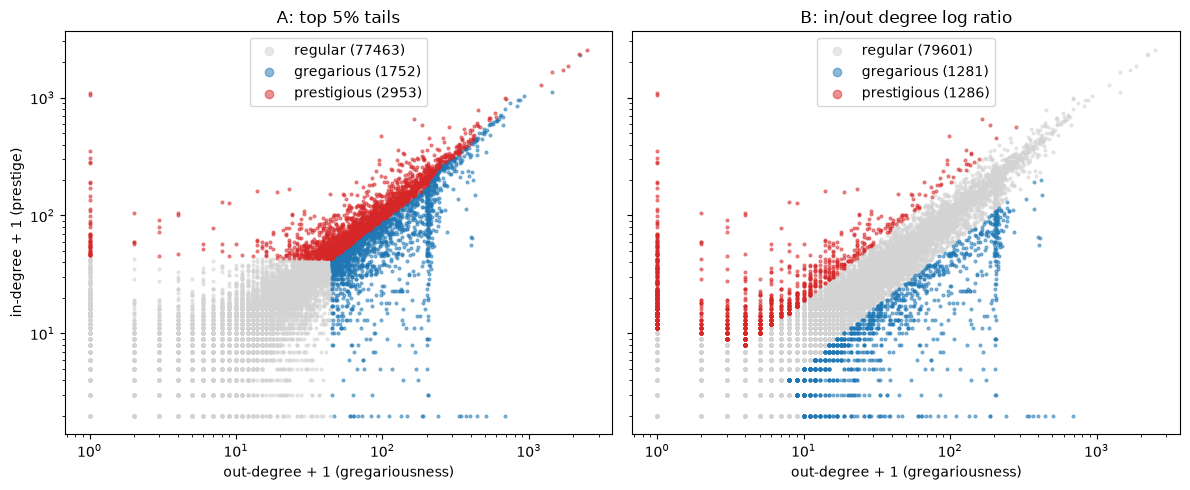

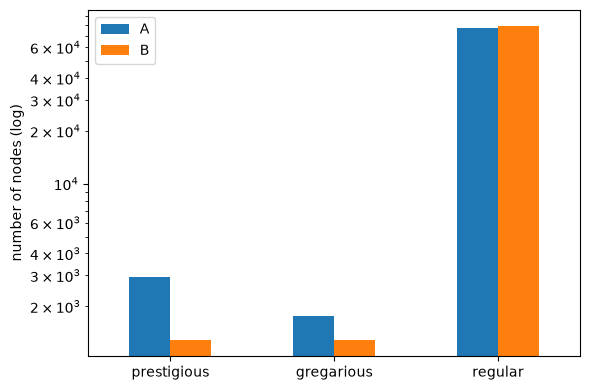

B            prestigious  gregarious  regular
A                                            
prestigious          226           0     2727
gregarious             0         481     1271
regular             1060         800    75603
agreement: 0.9287070392366858
                     in         out
A                                  
gregarious    90.884132  130.861301
prestigious  110.974602   94.345750
regular        4.947188    4.676930
                    in        out
B                                
gregarious   18.622170  61.256831
prestigious  34.430793   9.320373
regular      10.075602   9.795166


In [ ]:
colors = {"prestigious": "tab:red", "gregarious": "tab:blue", "regular": "lightgray"}
order = ["prestigious", "gregarious", "regular"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, m, title in zip(axes, ["A", "B"], ["A: top 5% tails", "B: in/out degree log ratio"]):
    for c in ["regular", "gregarious", "prestigious"]:
        s = df[df[m] == c]
        ax.scatter(s["out"] + 1, s["in"] + 1, s=4, alpha=0.5,
                   color=colors[c], label=f"{c} ({len(s)})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("out-degree + 1 (gregariousness)")
    ax.set_title(title); ax.legend(markerscale=3)
axes[0].set_ylabel("in-degree + 1 (prestige)")
plt.tight_layout(); plt.show()


sizes = pd.DataFrame({m: df[m].value_counts() for m in ["A", "B"]}).loc[order]
sizes.plot.bar(logy=True, figsize=(6, 4), rot=0)
plt.ylabel("number of nodes (log)"); plt.tight_layout(); plt.show()

ct = pd.crosstab(df["A"], df["B"]).loc[order, order]
print(ct)
print("agreement:", np.trace(ct.values) / ct.values.sum())

print(df.groupby("A")[["in", "out"]].mean())
print(df.groupby("B")[["in", "out"]].mean())